# Diagnóstico de cancro da mama — Active Learning com Human-in-the-Loop

**Inteligência Artificial Centrada no Humano** · Mestrado em Inteligência Artificial e Engenharia de Dados · FCTUC

Começa com poucas imagens anotadas e, em cada iteração, o modelo escolhe as imagens mais úteis e pede a label ao humano. Compara três estratégias de query do modAL (`uncertainty`, `entropy`, `margin`) e uma estratégia nossa focada nos casos malignos (`malignant`) com a escolha **ao acaso** (`random`), para ver se escolher bem poupa anotações.

> **Estado**
> - ✅ Feito: ciclo de Active Learning com 4 estratégias + random, 20 seeds, humano real ou simulado; curvas de aprendizagem.
> - ⬜ Falta: Grad-CAM (#4).

**Índice**
1. Configuração
2. Dados
3. Features da MobileNetV2
4. Experiências
5. Resultados
6. Humano no ciclo
7. Conclusões

## O que é Active Learning?

Anotar ecografias exige um médico e é caro e demorado. No **Passive Learning** (notebook 01), o modelo recebe todas as imagens já anotadas. No **Active Learning**, começa com poucas imagens anotadas e é o próprio modelo que escolhe quais quer ver anotadas a seguir: as que lhe trazem mais informação, normalmente aquelas em que está mais indeciso. O objetivo é chegar a um desempenho parecido com o de ter tudo anotado, com muito menos anotações.

### O ciclo, passo a passo
1. Treinar o modelo com um pequeno conjunto inicial de imagens anotadas, escolhidas ao acaso (`N_INITIAL`).
2. As restantes imagens de treino formam a **pool** (imagens "sem label").
3. Em cada iteração:
   - o modelo calcula as probabilidades para todas as imagens da pool e, com uma **estratégia de query**, escolhe as `N_INSTANCES` mais úteis;
   - o **humano** dá a classe correta dessas imagens (*Human-in-the-Loop*);
   - as imagens passam da pool para o conjunto anotado e o modelo volta a treinar;
   - mede-se o desempenho no conjunto de teste.
4. Repetir durante `N_QUERIES` iterações.

### As estratégias de query (biblioteca [modAL](https://modal-python.readthedocs.io/))
O modelo dá 3 probabilidades por imagem, por exemplo `[0.40, 0.35, 0.25]`. As estratégias medem a "indecisão" de formas diferentes:

| Estratégia | Escolhe as imagens com… | No exemplo |
|---|---|---|
| `uncertainty` | maior incerteza = 1 − probabilidade da classe mais provável | 1 − 0.40 = 0.60 |
| `margin` | menor diferença entre as duas classes mais prováveis | 0.40 − 0.35 = 0.05 |
| `entropy` | maior entropia (as probabilidades mais espalhadas pelas 3 classes) | −Σ p·log p |
| `malignant` (nossa) | probabilidade de **maligno** mais perto de 0.5 (o modelo não sabe se é cancro ou não) | — |
| `random` | escolha ao acaso, **sem** olhar para o modelo | — |

A estratégia `malignant` não vem do modAL: escrevemo-la nós (`malignant_sampling` em `src/active_learning.py`). As outras três tratam as 3 classes por igual, por isso podem gastar anotações em imagens indecisas entre normal e benigno, que não interessam para detetar cancro. A `malignant` só olha para a pergunta que importa ao projeto: *é maligno ou não?*

`random` é a referência: é o que se faria sem Active Learning (anotar imagens quaisquer). Uma estratégia só é útil se chegar ao mesmo desempenho com **menos** imagens anotadas do que `random`.

### O papel do humano
Com `HUMAN = True`, cada imagem escolhida aparece no notebook com a sugestão do modelo, e a pessoa escreve a classe correta. **O modelo aprende com a resposta da pessoa**, mesmo que esteja errada. Com `HUMAN = False`, a resposta é simulada com a label verdadeira do dataset, para se poder correr as experiências sem ninguém ao teclado.

### O que mudou em relação ao grupo de 2024 (e porquê)
O grupo de 2024 começava com **1000** imagens já anotadas, de um treino de ~2000, e pedia só **10** imagens ao humano (uma por iteração), treinando a CNN inteira de cada vez. Passar de 1000 para 1010 imagens anotadas quase não muda nada, por isso essas experiências não conseguiam mostrar se as estratégias ajudam. Também não havia comparação com `random`, nem repetições. Quando tentámos repetir esse desenho, cada treino demorava vários minutos e o processo acabou morto por falta de RAM.

Aqui:
- começamos com **20** imagens anotadas e pedimos **10 por iteração** durante **25 iterações** (até 270 imagens, cerca de 70% da pool);
- a pool tem só as **imagens originais**, sem as cópias rodadas, e **uma só imagem de cada ecografia repetida** (381 imagens): o humano anota imagens reais, e anotar outra vez a mesma ecografia (rodada ou noutro ficheiro) seria trabalho deitado fora;
- o conjunto inicial é escolhido ao acaso mas **estratificado**, para ter sempre imagens das 3 classes;
- o modelo é uma **regressão logística sobre as features da MobileNetV2 congelada** (secção 3), que treina em milissegundos. Assim cada experiência demora segundos e podemos repetir tudo com **20 seeds** e mostrar a média e a variação (com 5 seeds, a ordem das estratégias mudava de uma corrida para a outra: as diferenças entre elas são pequenas e era preciso mais repetições para as distinguir do acaso);
- comparamos sempre com `random`, com o **mesmo** conjunto inicial para todas as estratégias (mesma seed).

## 1. Configuração

A primeira célula prepara o ambiente local:
- junta a raiz do repositório ao `sys.path`, para se poder importar o código partilhado da pasta `src/` (o notebook deve ser aberto a partir da pasta `notebooks/`, com o kernel do `.venv`);
- lê os caminhos do dataset e da pasta de resultados de `src/config.py`;
- prepara a **GPU** com `setup_gpu()` (em `src/gpu.py`) e mostra se o treino vai correr na GPU ou no CPU.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent   # raiz do repositório (o notebook está em notebooks/)
sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, RESULTS_PATH
from src.gpu import setup_gpu

setup_gpu()

A treinar na GPU: NVIDIA GeForce RTX 3050 Laptop GPU


True

### Parâmetros
- **`N_INITIAL`**: imagens anotadas no início, escolhidas ao acaso.
- **`N_INSTANCES`**: imagens pedidas ao humano em cada iteração.
- **`N_QUERIES`**: nº de iterações. No fim há `N_INITIAL + N_INSTANCES × N_QUERIES` = 270 imagens anotadas.
- **`SEEDS`**: cada experiência é repetida com 20 conjuntos iniciais diferentes.

In [2]:
# Parâmetros
IMG_SIZE = 128
STRATEGIES = ["random", "uncertainty", "entropy", "margin", "malignant"]
N_INITIAL = 20          # imagens anotadas no início
N_INSTANCES = 10        # imagens pedidas ao humano por iteração
N_QUERIES = 25          # nº de iterações
SEEDS = list(range(20))
HUMAN = False           # True: pede a label a uma pessoa; False: simula o humano com a label do dataset

## 2. Dados

A mesma divisão treino/validação/teste do notebook 01 (mesma seed, por isso as mesmas imagens de teste), mas com `balance=False` (sem cópias rodadas) e `unique_train=True` (uma só imagem de cada grupo de ecografias repetidas): o treino fica com **381 imagens**, que formam a pool. O desequilíbrio entre classes é compensado no classificador (`class_weight="balanced"`), não com cópias.

In [3]:
import numpy as np
from src.data import CLASSES, load_dataset, summarize

x_train, x_val, x_test, y_train, y_val, y_test = load_dataset(DATA_PATH, size=IMG_SIZE, balance=False, unique_train=True)
summarize(x_train, x_val, x_test, y_train, y_val, y_test)

Treino: (381, 128, 128), validação: (127, 128, 128), teste: (149, 128, 128)
Memória das imagens: 43 MB
Treino: {'normal': 61, 'benign': 202, 'malignant': 118}
Validação: {'normal': 21, 'benign': 69, 'malignant': 37}
Teste: {'normal': 28, 'benign': 82, 'malignant': 39}


## 3. Features da MobileNetV2

Em vez de treinar uma CNN inteira em cada iteração, cada imagem passa **uma única vez** pela MobileNetV2 pré-treinada (sem a camada de saída) e é transformada num vetor de **1280 números** (*features*) que resume o seu conteúdo: texturas, contornos, formas. É a mesma rede que deu o melhor resultado no notebook 01.

Depois, o Active Learning treina só um classificador simples sobre esses vetores: uma **regressão logística** (`make_classifier` em `src/active_learning.py`), que aprende um peso por feature e por classe. É o equivalente a treinar só a última camada da rede, como na fase 1 do notebook 01.

**Regularização (`C`).** A regressão logística tem um parâmetro `C`: quanto menor, mais simples o modelo e menos risco de *overfitting*. Escolhemos `C` com o **conjunto de validação**, treinando com toda a pool. O teste não é usado para esta escolha.

In [4]:
from src.model import extract_features

f_train, f_val, f_test = extract_features(x_train, x_val, x_test)
print("Features:", f_train.shape, f_val.shape, f_test.shape)

Features: (381, 1280) (127, 1280) (149, 1280)


In [5]:
from src.active_learning import make_classifier
from src.evaluation import compute_metrics

val_accuracy = {}
for C in [0.001, 0.01, 0.1, 1.0]:
    clf = make_classifier(C).fit(f_train, y_train)
    val_accuracy[C] = float(np.mean(clf.predict(f_val) == y_val))
    print(f"C = {C:<6} accuracy de validação = {val_accuracy[C]:.3f}")
C = max(val_accuracy, key=val_accuracy.get)
print("C escolhido:", C)

# Referência: o mesmo classificador treinado com TODA a pool anotada
full = compute_metrics(y_test, make_classifier(C).fit(f_train, y_train).predict(f_test))
full

C = 0.001  accuracy de validação = 0.732


C = 0.01   accuracy de validação = 0.756
C = 0.1    accuracy de validação = 0.748
C = 1.0    accuracy de validação = 0.740
C escolhido: 0.01


{'accuracy': 0.7785234899328859,
 'recall_macro': 0.7616739628934751,
 'f1_macro': 0.7541172502192538,
 'recall_malignant': 0.717948717948718,
 'false_negatives': 11}

## 4. Experiências

Para cada estratégia e cada seed, `run_active_learning` corre o ciclo completo e regista as métricas no teste depois de cada iteração. Com a mesma seed, todas as estratégias começam com as **mesmas 20 imagens**, para a comparação ser justa.

São 5 estratégias × 20 seeds = 100 experiências, e cada uma demora cerca de um segundo. Os resultados ficam em `results/active_learning.json`.

In [6]:
import time
from src.active_learning import run_active_learning
from src.evaluation import save_json

results = {strategy: [] for strategy in STRATEGIES}   # results[estratégia] = [history de cada seed]
start = time.time()
for strategy in STRATEGIES:
    for seed in SEEDS:
        results[strategy].append(run_active_learning(strategy, f_train, y_train, f_test, y_test, n_initial=N_INITIAL,
                                                     n_instances=N_INSTANCES, n_queries=N_QUERIES, C=C, seed=seed))
print(f"Tempo total: {time.time() - start:.0f} s")

save_json({"params": {"img_size": IMG_SIZE, "n_initial": N_INITIAL, "n_instances": N_INSTANCES,
                      "n_queries": N_QUERIES, "seeds": SEEDS, "C": C},
           "full_pool": full, "results": results}, RESULTS_PATH / "active_learning.json")

Tempo total: 94 s


## 5. Resultados

### 5.1 Curvas de aprendizagem
Cada linha mostra o desempenho no teste em função do **nº de imagens anotadas**: a média das 20 seeds, com a sombra a mostrar ± 1 desvio padrão. A linha pontilhada preta é o resultado com a pool toda anotada.

**Como ler:** uma estratégia é melhor do que `random` (cinzento tracejado) se a sua curva estiver **acima**, ou seja, se para o mesmo nº de anotações tiver melhor desempenho, ou se chegar ao mesmo desempenho com menos anotações.

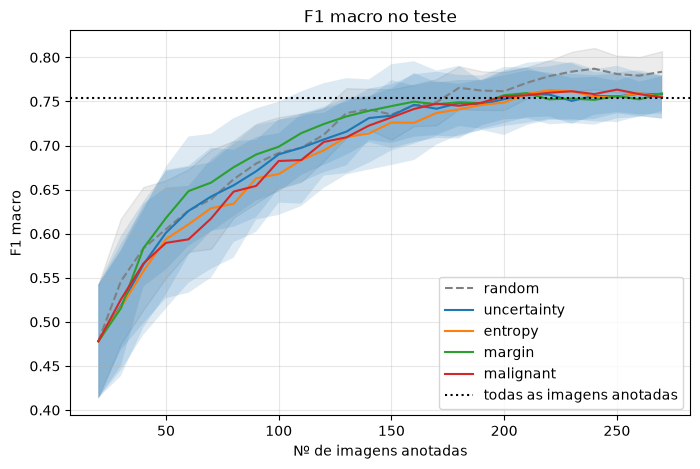

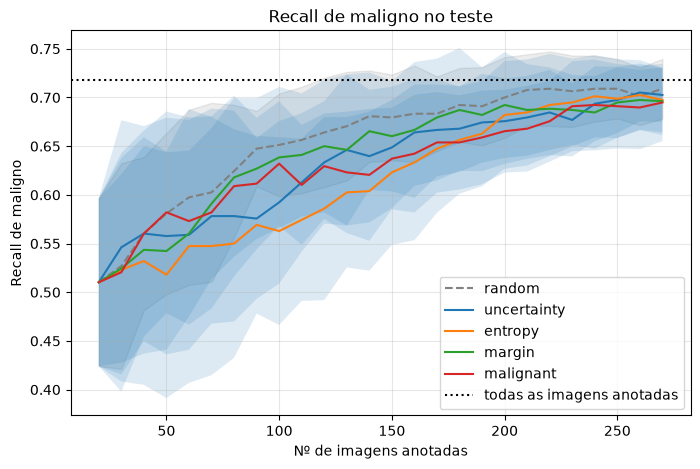

In [7]:
from src.evaluation import plot_learning_curves

plot_learning_curves(results, "f1_macro", "F1 macro no teste", reference=full["f1_macro"], ylabel="F1 macro")
plot_learning_curves(results, "recall_malignant", "Recall de maligno no teste", reference=full["recall_malignant"],
                     ylabel="Recall de maligno")

### 5.2 Tabela
F1 macro e recall de maligno (média ± desvio padrão das 20 seeds) para alguns nºs de imagens anotadas. A última coluna é quantas imagens anotadas cada estratégia precisa, em média, para chegar a **95% do F1 obtido com a pool toda**.

In [8]:
checkpoints = [50, 100, 150, 200, 270]
n_labeled = np.array(results["random"][0]["n_labeled"])
target = 0.95 * full["f1_macro"]

def mean_curve(strategy, metric):
    return np.mean([run[metric] for run in results[strategy]], axis=0)

def std_curve(strategy, metric):
    return np.std([run[metric] for run in results[strategy]], axis=0)

def table(metric, title, with_target=False):
    print(title)
    print(f"{'estratégia':<13}" + "".join(f"{n:>14}" for n in checkpoints) + (f"{'anotações p/ alvo':>20}" if with_target else ""))
    for strategy in STRATEGIES:
        mean, std = mean_curve(strategy, metric), std_curve(strategy, metric)
        row = f"{strategy:<13}" + "".join(f"{mean[n_labeled == n][0]:>8.3f} ± {std[n_labeled == n][0]:.2f}" for n in checkpoints)
        if with_target:
            reached = n_labeled[mean >= target]
            row += f"{(str(reached[0]) if len(reached) else '> ' + str(n_labeled[-1])):>20}"
        print(row)
    print()

table("f1_macro", f"F1 macro (média ± desvio padrão de {len(SEEDS)} seeds); alvo = 95% de {full['f1_macro']:.3f} = {target:.3f}", with_target=True)
table("recall_malignant", "Recall de maligno")

F1 macro (média ± desvio padrão de 20 seeds); alvo = 95% de 0.754 = 0.716
estratégia               50           100           150           200           270   anotações p/ alvo
random          0.605 ± 0.06   0.692 ± 0.04   0.735 ± 0.03   0.762 ± 0.02   0.784 ± 0.02                 130
uncertainty     0.601 ± 0.07   0.690 ± 0.04   0.734 ± 0.03   0.753 ± 0.03   0.758 ± 0.02                 140
entropy         0.594 ± 0.08   0.668 ± 0.05   0.726 ± 0.05   0.749 ± 0.04   0.755 ± 0.02                 150
margin          0.618 ± 0.06   0.699 ± 0.05   0.745 ± 0.05   0.757 ± 0.03   0.759 ± 0.02                 120
malignant       0.590 ± 0.06   0.682 ± 0.05   0.732 ± 0.04   0.756 ± 0.03   0.755 ± 0.02                 140

Recall de maligno
estratégia               50           100           150           200           270
random          0.581 ± 0.08   0.651 ± 0.05   0.679 ± 0.04   0.700 ± 0.04   0.709 ± 0.03
uncertainty     0.558 ± 0.12   0.592 ± 0.08   0.649 ± 0.06   0.676 ± 0.04   0.703 ± 0

### 5.3 Que imagens escolhe cada estratégia?
Distribuição das classes nas imagens pedidas ao humano (todas as seeds juntas), comparada com a distribuição da pool. `random` segue as proporções da pool; as outras estratégias não.

In [9]:
print(f"{'pool':<13}", {name: f"{np.mean(y_train == i):.0%}" for i, name in enumerate(CLASSES)})
for strategy in STRATEGIES:
    queried = np.concatenate([y_train[run["queried"]] for run in results[strategy]])
    shares = {name: f"{np.mean(queried == i):.0%}" for i, name in enumerate(CLASSES)}
    print(f"{strategy:<13}", shares)

pool          {'normal': '16%', 'benign': '53%', 'malignant': '31%'}
random        {'normal': '16%', 'benign': '53%', 'malignant': '30%'}
uncertainty   {'normal': '20%', 'benign': '48%', 'malignant': '32%'}
entropy       {'normal': '21%', 'benign': '48%', 'malignant': '32%'}
margin        {'normal': '20%', 'benign': '48%', 'malignant': '32%'}
malignant     {'normal': '16%', 'benign': '47%', 'malignant': '38%'}


### 5.4 Matriz de confusão
No fim das 25 iterações (270 imagens anotadas), seed 0, para `random` e para a estratégia com melhor F1 médio final.

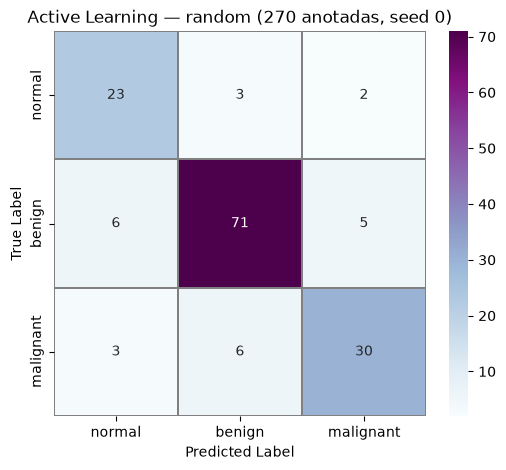

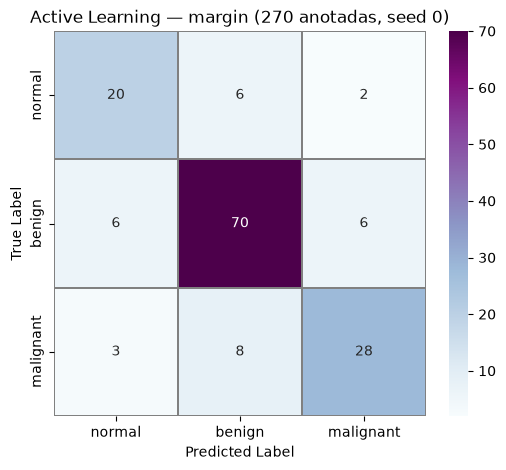

In [10]:
from src.evaluation import plot_confusion_matrix

best = max(STRATEGIES[1:], key=lambda s: mean_curve(s, "f1_macro")[-1])
for strategy in ["random", best]:
    plot_confusion_matrix(y_test, results[strategy][0]["y_pred"], title=f"Active Learning — {strategy} (270 anotadas, seed 0)")

## 6. Humano no ciclo

Com `HUMAN = True` (no início do notebook), esta célula corre um ciclo curto com a estratégia `margin`: em cada iteração aparecem as imagens escolhidas, com a sugestão do modelo, e é preciso escrever a classe (0, 1 ou 2). O modelo aprende com as respostas dadas. Com `HUMAN = False` não faz nada.

In [11]:
if HUMAN:
    human_run = run_active_learning("margin", f_train, y_train, f_test, y_test, n_initial=N_INITIAL, n_instances=3,
                                    n_queries=2, C=C, seed=0, human=True, images=x_train)
    print("F1 macro no teste depois de cada iteração:", [round(v, 3) for v in human_run["f1_macro"]])

## 7. Conclusões

**Referência:** o mesmo classificador (regressão logística sobre as features da MobileNetV2) treinado com a pool toda anotada (381 imagens) tem accuracy 0.78, F1 macro 0.75 e recall de maligno 0.72, perto da MobileNetV2 com fine-tuning do notebook 01 (0.79), com um modelo que treina em milissegundos.

1. **O Active Learning não poupa anotações em relação à escolha ao acaso.** Para chegar a 95% do F1 obtido com tudo anotado, `margin` precisa de 120 imagens anotadas e `random` de 130; `uncertainty` e `malignant` precisam de 140 e `entropy` de 150. Até às ~150 imagens, `margin` fica 1 ponto de F1 acima de `random`, menos do que o desvio padrão entre seeds (0.03–0.06). A partir das 200 imagens, `random` é a melhor (0.784 com 270, contra ~0.757 das outras).
2. **As estratégias de incerteza detetam um pouco menos cancros do que `random`.** Até às 150 imagens anotadas, o recall de maligno de `random` é igual ou superior ao das outras estratégias (até 9 pontos acima); no fim (270), ficam todas perto de 0.70.
3. **A estratégia `malignant` pede mais imagens malignas ao humano** (38%, contra 31% na pool), mas isso não se traduz em melhor recall de maligno.
4. **O que mudou ao corrigir o leakage.** Com a divisão antiga (com ecografias repetidas entre treino e teste), as estratégias pareciam poupar ~24% das anotações. Com a divisão por grupos e uma só imagem por ecografia na pool, essa vantagem desaparece. Também testámos (fora do notebook) pedir uma imagem de cada vez e a estratégia do modAL que combina incerteza com diversidade (`uncertainty_batch_sampling`): os resultados ficaram sempre a ±1 ponto de F1 de `random`.
5. **Porque é que o Active Learning não ajuda aqui?** Hipóteses (não provadas): (a) as features da MobileNetV2 já separam bem as classes, por isso qualquer amostra ao acaso é informativa; (b) as imagens "mais indecisas" são muitas vezes as mais ambíguas ou com labels duvidosas (o dataset tem labels contraditórias, ver o notebook 00), e ensinar o modelo com elas não ajuda; (c) com só ~380 imagens na pool, há pouco por onde escolher.
6. **Lição para o Human-in-the-Loop:** pedir ao humano as imagens em que o modelo está mais indeciso não garante poupar anotações nem detetar mais cancros. Num problema médico, é preciso comparar sempre com a escolha ao acaso e avaliar a classe que importa (maligno), e não só a accuracy média.
7. **Em relação ao grupo de 2024:** o desenho deles (1000 imagens iniciais + 10 pedidas, sem `random`, uma corrida, com data leakage) não conseguia mostrar se o Active Learning ajudava, e a vantagem que encontraram sobre o Passive Learning vinha sobretudo de o modelo ativo ser treinado muito mais vezes.